# Loading the Dataset

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path

In [2]:
RANDOM_STATE = 42
DATA_PATH = Path("../data/processed/sparcs_2024_final.parquet")

df = pd.read_parquet(DATA_PATH)
print(df.shape)
df.head()

(1993483, 15)


,permanent_facility_id,age_group,zip_code,gender,race,ethnicity,type_of_admission,ccsr_diagnosis_code,apr_medical_surgical,payment_typology_1,emergency_department_indicator,ccsr_procedure_code,payment_typology_2,payment_typology_3,los
0,001139,0-17,OOS,F,White,Not Span/Hispanic,Emergency,SYM002,Medical,Private Health Insurance,Y,No procedure recorded,No second payer,No third payer,1
1,001628,0-17,113,M,White,Spanish/Hispanic,Emergency,SYM002,Medical,Medicaid,Y,No procedure recorded,No second payer,No third payer,2
2,001458,70 or Older,100,M,White,Not Span/Hispanic,Emergency,SYM002,Medical,Medicare,Y,ADM012,Private Health Insurance,No third payer,2
3,001464,0-17,100,F,Other Race,Not Span/Hispanic,Emergency,SYM002,Medical,Private Health Insurance,Y,CNS002,No second payer,No third payer,1
4,001466,18-29,100,F,Other Race,Spanish/Hispanic,Emergency,SYM002,Medical,Medicare,Y,ADM021,No second payer,No third payer,1


In [3]:
POST_ADMISSION = ["ccsr_diagnosis_code", "apr_medical_surgical", "ccsr_procedure_code"]
TARGET = 'los'
ADMISSION = [col for col in df.columns if col not in (POST_ADMISSION+[TARGET])]
y = df[TARGET]

In [4]:
los_bins = pd.cut(y, bins=[0, 1, 2, 3, 5, 7, 14, 30, 120], labels=False)
print(los_bins.value_counts().sort_index())

los
0    352579
1    360361
2    301000
3    352622
4    197177
5    267800
6    123904
7     38040
Name: count, dtype: int64


# Choosing the Percentage of the Data for Training

In [6]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from catboost import CatBoostRegressor

In [7]:
indices = np.arange(len(df))
train_val_idx, test_idx = train_test_split(
    indices,
    test_size=0.20,
    stratify=los_bins,
    random_state=RANDOM_STATE,
)
train_idx, val_idx = train_test_split(
    train_val_idx,
    test_size=0.25,
    stratify=los_bins.iloc[train_val_idx],
    random_state=RANDOM_STATE,
)

### Strictly pre-admission problem framing

In [9]:
X = df[ADMISSION]

X_train = X.iloc[train_idx].copy()
X_val = X.iloc[val_idx].copy()
X_test = X.iloc[test_idx].copy()
y_train = y.iloc[train_idx].copy()
y_val = y.iloc[val_idx].copy()
y_test = y.iloc[test_idx].copy()

X_train = X_train.reset_index(drop=True)
X_val = X_val.reset_index(drop=True)
X_test = X_test.reset_index(drop=True)
y_train = y_train.reset_index(drop=True)
y_val = y_val.reset_index(drop=True)
y_test = y_test.reset_index(drop=True)

In [11]:
PERCENTAGES = [0.01, 0.02, 0.05, 0.08, 0.10, 0.15, 0.20]

def create_nested_samples(y_train, train_bins, percentages):
    rng = np.random.default_rng(RANDOM_STATE)
    train_bins = np.asarray(train_bins)

    strata_indices = {}

    for bin_label in np.unique(train_bins):
        idx = np.where(train_bins == bin_label)[0]
        strata_indices[bin_label] = rng.permutation(idx)

    samples = {}

    for pct in percentages:
        selected_indices = []

        for shuffled_idx in strata_indices.values():
            n_samples = max(1, int(round(len(shuffled_idx) * pct)))
            selected_indices.extend(shuffled_idx[:n_samples])

        samples[pct] = rng.permutation(selected_indices)

    return samples


train_bins = los_bins.iloc[train_idx].to_numpy()

samples = create_nested_samples(y_train, train_bins, PERCENTAGES)

for pct, idx in samples.items():
    print(f"{pct:.0%}: {len(idx):,} rows")

1%: 11,960 rows
2%: 23,921 rows
5%: 59,804 rows
8%: 95,686 rows
10%: 119,609 rows
15%: 179,414 rows
20%: 239,217 rows


In [12]:
import time

def create_model():
    return CatBoostRegressor(
        iterations=1500,
        learning_rate=0.05,
        depth=8,
        loss_function="RMSE",
        eval_metric="MAE",
        random_seed=RANDOM_STATE,
        verbose=False,
        allow_writing_files=False,
        thread_count=-1
    )


admission_results = []
admission_models = {}

for pct, sample_idx in samples.items():

    X_subset = X_train.iloc[sample_idx]
    y_subset = y_train.iloc[sample_idx]

    model = create_model()

    start_time = time.perf_counter()

    model.fit(
        X_subset,
        y_subset,
        cat_features=list(X_train.columns),
        eval_set=(X_val, y_val),
        early_stopping_rounds=100,
        use_best_model=True,
        verbose=False
    )

    training_time = time.perf_counter() - start_time

    val_predictions = model.predict(X_val)

    mae = mean_absolute_error(y_val, val_predictions)
    rmse = np.sqrt(mean_squared_error(y_val, val_predictions))
    r2 = r2_score(y_val, val_predictions)

    admission_results.append({
        "Training Percentage": pct,
        "Training Rows": len(sample_idx),
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2,
        "Training Time (sec)": training_time,
        "Best Iteration": model.best_iteration_
    })

    admission_models[pct] = model

    print(
        f"{pct:>5.0%} | "
        f"Rows: {len(sample_idx):>8,} | "
        f"MAE: {mae:.4f} | "
        f"RMSE: {rmse:.4f} | "
        f"R2: {r2:.4f} | "
        f"Time: {training_time:.1f}s"
    )

admission_results_df = pd.DataFrame(admission_results)

   1% | Rows:   11,960 | MAE: 4.4516 | RMSE: 8.5309 | R2: 0.0621 | Time: 162.1s
   2% | Rows:   23,921 | MAE: 4.3832 | RMSE: 8.4815 | R2: 0.0729 | Time: 248.0s
   5% | Rows:   59,804 | MAE: 4.3619 | RMSE: 8.4425 | R2: 0.0814 | Time: 252.4s
   8% | Rows:   95,686 | MAE: 4.3182 | RMSE: 8.4093 | R2: 0.0886 | Time: 843.8s
  10% | Rows:  119,609 | MAE: 4.3109 | RMSE: 8.4027 | R2: 0.0900 | Time: 1026.9s
  15% | Rows:  179,414 | MAE: 4.3011 | RMSE: 8.3820 | R2: 0.0945 | Time: 1219.4s
  20% | Rows:  239,217 | MAE: 4.2929 | RMSE: 8.3707 | R2: 0.0970 | Time: 1342.9s


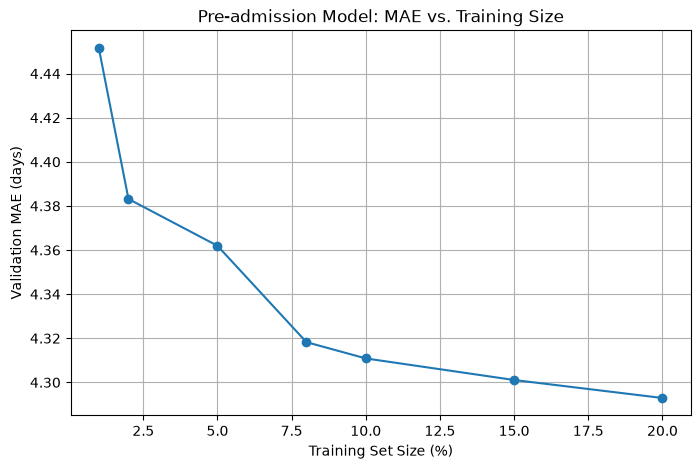

In [17]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    admission_results_df["Training Percentage"] * 100,
    admission_results_df["MAE"],
    marker="o"
)

plt.xlabel("Training Set Size (%)")
plt.ylabel("Validation MAE (days)")
plt.title("Pre-admission Model: MAE vs. Training Size")
plt.grid(True)
plt.show()

### Pre-discharge problem framing

In [8]:
POST_FEATURES = ADMISSION + POST_ADMISSION

X = df[POST_FEATURES]

X_train = X.iloc[train_idx].copy()
X_val = X.iloc[val_idx].copy()
X_test = X.iloc[test_idx].copy()

y_train = y.iloc[train_idx].copy()
y_val = y.iloc[val_idx].copy()
y_test = y.iloc[test_idx].copy()

# Reset indices
X_train = X_train.reset_index(drop=True)
X_val = X_val.reset_index(drop=True)
X_test = X_test.reset_index(drop=True)

y_train = y_train.reset_index(drop=True)
y_val = y_val.reset_index(drop=True)
y_test = y_test.reset_index(drop=True)

In [18]:
train_bins = los_bins.iloc[train_idx].to_numpy()

samples = create_nested_samples(y_train, train_bins, PERCENTAGES)

for pct, idx in samples.items():
    print(f"{pct:.0%}: {len(idx):,} rows")

1%: 11,960 rows
2%: 23,921 rows
5%: 59,804 rows
8%: 95,686 rows
10%: 119,609 rows
15%: 179,414 rows
20%: 239,217 rows


In [19]:
post_admission_results = []
post_admission_models = {}

for pct, sample_idx in samples.items():

    X_subset = X_train.iloc[sample_idx]
    y_subset = y_train.iloc[sample_idx]

    model = create_model()

    start_time = time.perf_counter()

    model.fit(
        X_subset,
        y_subset,
        cat_features=list(X_train.columns),
        eval_set=(X_val, y_val),
        early_stopping_rounds=100,
        use_best_model=True,
        verbose=False
    )

    training_time = time.perf_counter() - start_time

    val_predictions = model.predict(X_val)

    mae = mean_absolute_error(y_val, val_predictions)
    rmse = np.sqrt(mean_squared_error(y_val, val_predictions))
    r2 = r2_score(y_val, val_predictions)

    post_admission_results.append({
        "Training Percentage": pct,
        "Training Rows": len(sample_idx),
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2,
        "Training Time (sec)": training_time,
        "Best Iteration": model.best_iteration_
    })

    post_admission_models[pct] = model

    print(
        f"{pct:>5.0%} | "
        f"Rows: {len(sample_idx):>8,} | "
        f"MAE: {mae:.4f} | "
        f"RMSE: {rmse:.4f} | "
        f"R2: {r2:.4f} | "
        f"Time: {training_time:.1f}s"
    )

post_admission_results_df = pd.DataFrame(post_admission_results)

   1% | Rows:   11,960 | MAE: 3.8486 | RMSE: 7.8444 | R2: 0.2070 | Time: 262.6s
   2% | Rows:   23,921 | MAE: 3.7592 | RMSE: 7.7432 | R2: 0.2273 | Time: 222.1s
   5% | Rows:   59,804 | MAE: 3.6560 | RMSE: 7.5648 | R2: 0.2625 | Time: 1023.2s
   8% | Rows:   95,686 | MAE: 3.5797 | RMSE: 7.5007 | R2: 0.2749 | Time: 1466.1s
  10% | Rows:  119,609 | MAE: 3.5638 | RMSE: 7.4681 | R2: 0.2812 | Time: 1513.1s
  15% | Rows:  179,414 | MAE: 3.5458 | RMSE: 7.4132 | R2: 0.2917 | Time: 1784.4s
  20% | Rows:  239,217 | MAE: 3.5355 | RMSE: 7.3808 | R2: 0.2979 | Time: 1945.0s


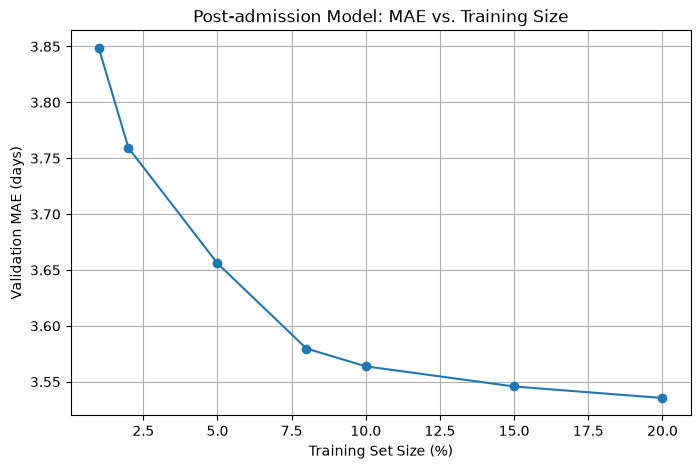

In [21]:
plt.figure(figsize=(8, 5))

plt.plot(
    post_admission_results_df["Training Percentage"] * 100,
    post_admission_results_df["MAE"],
    marker="o"
)

plt.xlabel("Training Set Size (%)")
plt.ylabel("Validation MAE (days)")
plt.title("Post-admission Model: MAE vs. Training Size")
plt.grid(True)
plt.show()

In [24]:
test_results = []

for pct, model in post_admission_models.items():
    test_predictions = model.predict(X_test)

    test_mae = mean_absolute_error(y_test, test_predictions)
    test_rmse = np.sqrt(mean_squared_error(y_test, test_predictions))
    test_r2 = r2_score(y_test, test_predictions)

    test_results.append({
        "Training Percentage": pct,
        "Training Rows": len(samples[pct]),
        "Test MAE": test_mae,
        "Test RMSE": test_rmse,
        "Test R2": test_r2
    })

test_results_df = pd.DataFrame(test_results)

display(test_results_df.round(4))

,Training Percentage,Training Rows,Test MAE,Test RMSE,Test R2
0,0.01,11960,3.8408,7.7852,0.2117
1,0.02,23921,3.7529,7.6859,0.2317
2,0.05,59804,3.6506,7.5102,0.2664
3,0.08,95686,3.5747,7.4482,0.2785
4,0.10,119609,3.5610,7.4161,0.2847
5,0.15,179414,3.5441,7.3702,0.2935
6,0.20,239217,3.5319,7.3341,0.3004


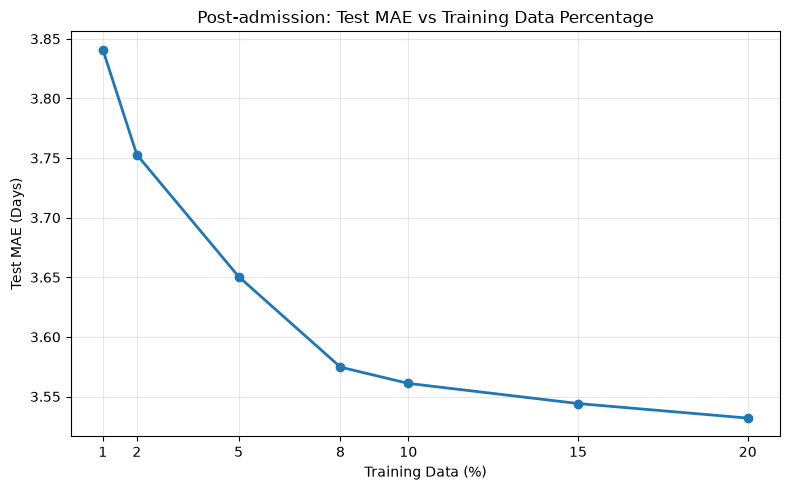

In [27]:
plt.figure(figsize=(8, 5))

plt.plot(
    test_results_df["Training Percentage"] * 100,
    test_results_df["Test MAE"],
    marker="o",
    linewidth=2
)

plt.xlabel("Training Data (%)")
plt.ylabel("Test MAE (Days)")
plt.title("Post-admission: Test MAE vs Training Data Percentage")
plt.xticks(test_results_df["Training Percentage"] * 100)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [32]:
model = post_admission_models[0.05]

feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

display(feature_importance.head(15))

,Feature,Importance
13,ccsr_procedure_code,19.066513
11,ccsr_diagnosis_code,18.400772
0,permanent_facility_id,12.453304
12,apr_medical_surgical,11.968318
6,type_of_admission,9.709124
1,age_group,5.789324
4,race,4.485089
2,zip_code,3.715703
7,payment_typology_1,3.706108
9,payment_typology_2,3.321582


In [9]:
PERCENTAGES_L1 = [0.01, 0.02, 0.03, 0.04, 0.05, 0.06, 0.07, 0.08]

from sklearn.compose import ColumnTransformer
from sklearn.model_selection import KFold
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, TargetEncoder

AGE_ORDER = ["0-17", "18-29", "30-49", "50-69", "70 or Older"]
HIGH_CARDINALITY = ["permanent_facility_id", "ccsr_diagnosis_code", "ccsr_procedure_code", "zip_code"]

def make_preprocessor(features):
    ordinal = ["age_group"]
    high = [c for c in features if c in HIGH_CARDINALITY]
    low = [c for c in features if c not in ordinal + high]

    return ColumnTransformer([
        ("age", OrdinalEncoder(categories=[AGE_ORDER]), ordinal),
        ("low", OneHotEncoder(min_frequency=100, handle_unknown="infrequent_if_exist",
                              sparse_output=False), low),
        ("high", TargetEncoder(target_type="continuous",
                               cv=KFold(5, shuffle=True, random_state=RANDOM_STATE)), high),
    ])

In [13]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso

def create_l1_model(features, alpha):

    return Pipeline([
        ("preprocessor", make_preprocessor(features)),
        ("scaler", StandardScaler(with_mean=False)),
        ("lasso", Lasso(
            alpha=alpha,
            max_iter=20000,
            tol=1e-4
        ))
    ])

train_bins = los_bins.iloc[train_idx].to_numpy()

samples_l1 = create_nested_samples(
    y_train,
    train_bins,
    PERCENTAGES_L1
)

for pct, idx in samples_l1.items():
    print(f"{pct:>6.1%}: {len(idx):,} rows")

  1.0%: 11,960 rows
  2.0%: 23,921 rows
  3.0%: 35,882 rows
  4.0%: 47,844 rows
  5.0%: 59,804 rows
  6.0%: 71,765 rows
  7.0%: 83,726 rows
  8.0%: 95,686 rows


In [15]:
import time

l1_results = []
l1_models = {}
l1_alpha_results = []

features = X_train.columns.tolist()

for pct, sample_idx in samples_l1.items():

    print(f"\n{'='*65}")
    print(f"Training percentage: {pct:.1%}")
    print(f"Training rows: {len(sample_idx):,}")
    print(f"{'='*65}")

    X_subset = X_train.iloc[sample_idx]
    y_subset = y_train.iloc[sample_idx]

    best_model = None
    best_alpha = None
    best_mae = float("inf")

    start_time = time.perf_counter()

    for alpha in ALPHAS:

        model = create_l1_model(
            features=features,
            alpha=alpha
        )

        model.fit(X_subset, y_subset)

        val_predictions = model.predict(X_val)

        mae = mean_absolute_error(
            y_val,
            val_predictions
        )

        rmse = np.sqrt(
            mean_squared_error(y_val, val_predictions)
        )

        r2 = r2_score(
            y_val,
            val_predictions
        )

        l1_alpha_results.append({
            "Training Percentage": pct,
            "Training Rows": len(sample_idx),
            "Alpha": alpha,
            "MAE": mae,
            "RMSE": rmse,
            "R2": r2
        })

        if mae < best_mae:
            best_mae = mae
            best_alpha = alpha
            best_model = model

    training_time = time.perf_counter() - start_time

    val_predictions = best_model.predict(X_val)

    mae = mean_absolute_error(
        y_val,
        val_predictions
    )

    rmse = np.sqrt(
        mean_squared_error(y_val, val_predictions)
    )

    r2 = r2_score(
        y_val,
        val_predictions
    )

    coefficients = best_model.named_steps["lasso"].coef_

    nonzero_features = np.count_nonzero(coefficients)

    negative_predictions = np.mean(val_predictions < 0)

    l1_results.append({
        "Training Percentage": pct,
        "Training Rows": len(sample_idx),
        "Best Alpha": best_alpha,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2,
        "Nonzero Coefficients": nonzero_features,
        "Negative Prediction Rate": negative_predictions,
        "Training Time (sec)": training_time
    })

    l1_models[pct] = best_model

    print(
        f"Best Alpha: {best_alpha:.5f} | "
        f"MAE: {mae:.4f} | "
        f"RMSE: {rmse:.4f} | "
        f"R2: {r2:.4f}"
    )

    print(
        f"Nonzero Coefficients: {nonzero_features:,} | "
        f"Negative Predictions: {negative_predictions:.2%} | "
        f"Time: {training_time:.1f}s"
    )

l1_results_df = pd.DataFrame(l1_results)

l1_alpha_results_df = pd.DataFrame(l1_alpha_results)


Training percentage: 1.0%
Training rows: 11,960
Best Alpha: 0.10000 | MAE: 4.0605 | RMSE: 7.9423 | R2: 0.1870
Nonzero Coefficients: 17 | Negative Predictions: 1.05% | Time: 37.6s

Training percentage: 2.0%
Training rows: 23,921
Best Alpha: 0.10000 | MAE: 4.0091 | RMSE: 7.8751 | R2: 0.2007
Nonzero Coefficients: 16 | Negative Predictions: 1.35% | Time: 56.0s

Training percentage: 3.0%
Training rows: 35,882
Best Alpha: 0.10000 | MAE: 3.9874 | RMSE: 7.8292 | R2: 0.2100
Nonzero Coefficients: 17 | Negative Predictions: 1.69% | Time: 39.6s

Training percentage: 4.0%
Training rows: 47,844
Best Alpha: 0.10000 | MAE: 3.9827 | RMSE: 7.8153 | R2: 0.2128
Nonzero Coefficients: 17 | Negative Predictions: 1.87% | Time: 41.1s

Training percentage: 5.0%
Training rows: 59,804
Best Alpha: 0.10000 | MAE: 3.9707 | RMSE: 7.8126 | R2: 0.2134
Nonzero Coefficients: 16 | Negative Predictions: 1.77% | Time: 54.2s

Training percentage: 6.0%
Training rows: 71,765
Best Alpha: 0.10000 | MAE: 3.9678 | RMSE: 7.7996 | 

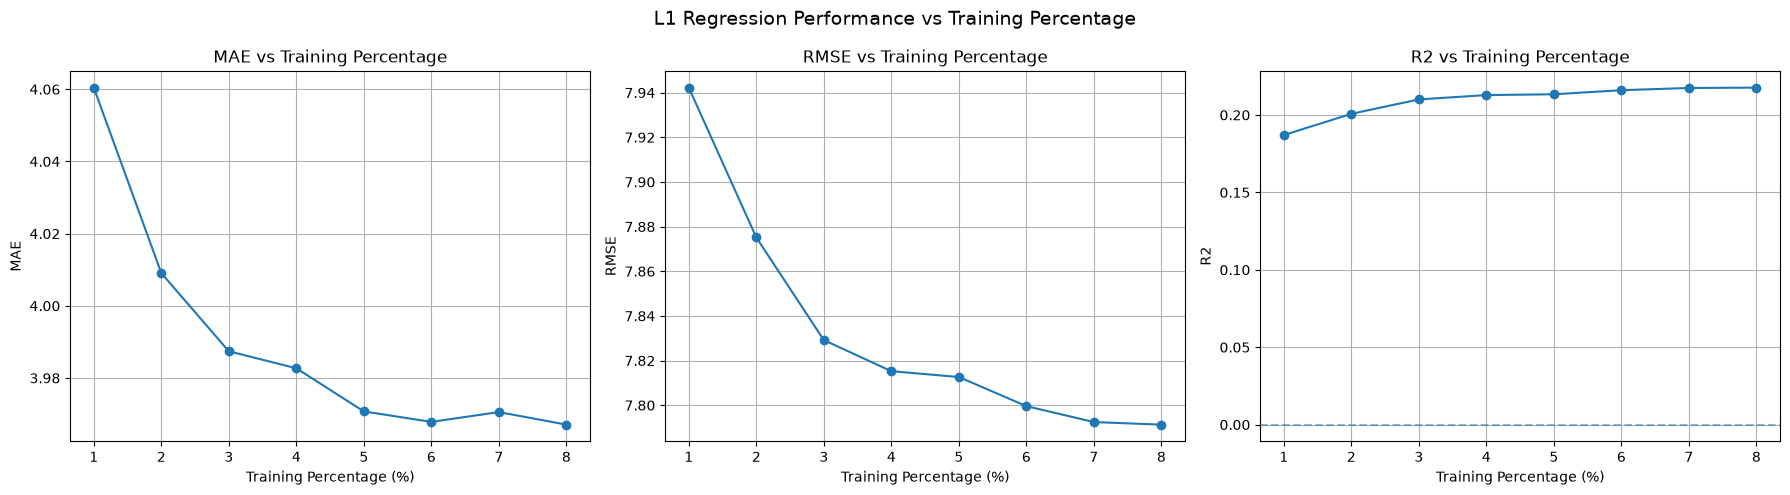

In [17]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

metrics = ["MAE", "RMSE", "R2"]

for ax, metric in zip(axes, metrics):

    ax.plot(
        l1_results_df["Training Percentage"] * 100,
        l1_results_df[metric],
        marker="o"
    )

    ax.set_xlabel("Training Percentage (%)")
    ax.set_ylabel(metric)
    ax.set_title(f"{metric} vs Training Percentage")
    ax.grid(True)

    if metric == "R2":
        ax.axhline(0, linestyle="--", alpha=0.5)

plt.suptitle(
    "L1 Regression Performance vs Training Percentage",
    fontsize=14
)

plt.tight_layout()
plt.show()